In [1]:
# Cellule 1 - Imports
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
import os

warnings.filterwarnings('ignore')
os.makedirs('deepsmote_v2', exist_ok=True)

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, Model
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from tensorflow.keras.utils import to_categorical

from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.decomposition import PCA
from sklearn.metrics import (accuracy_score,
                             balanced_accuracy_score,
                             f1_score,
                             matthews_corrcoef,
                             classification_report,
                             confusion_matrix,
                             roc_auc_score)
from sklearn.utils.class_weight import compute_class_weight

import subprocess
subprocess.run(['pip', 'install', 'imbalanced-learn', '-q'])
from imblearn.over_sampling import SMOTE

print('TensorFlow :', tf.__version__)
print('GPU        :', tf.config.list_physical_devices('GPU'))
print('Imports OK')

TensorFlow : 2.20.0
GPU        : [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Imports OK


In [2]:
# Cellule 2 - Chargement depuis Google Drive
from google.colab import drive
drive.mount('/content/drive')

BASE = '/content/drive/MyDrive/UCI HAR Dataset'

with open(f'{BASE}/features.txt') as f:
    features_raw = [line.strip().split(' ', 1)[1] for line in f.readlines()]

seen = {}
features_unique = []
for feat in features_raw:
    if feat in seen:
        seen[feat] += 1
        features_unique.append(feat + '_' + str(seen[feat]))
    else:
        seen[feat] = 0
        features_unique.append(feat)

X_train_raw = pd.read_csv(
    f'{BASE}/train/X_train.txt',
    sep=r'\s+', engine='python',
    header=None, names=features_unique
)
X_test_raw = pd.read_csv(
    f'{BASE}/test/X_test.txt',
    sep=r'\s+', engine='python',
    header=None, names=features_unique
)
y_train_raw = pd.read_csv(f'{BASE}/train/y_train.txt', header=None)[0]
y_test_raw  = pd.read_csv(f'{BASE}/test/y_test.txt',   header=None)[0]

CLASS_NAMES = ['LAYING', 'SITTING', 'STANDING', 'WALKING',
               'WALKING_DOWNSTAIRS', 'WALKING_UPSTAIRS']

le          = LabelEncoder()
y_train     = le.fit_transform(y_train_raw)
y_test      = le.transform(y_test_raw)
NUM_CLASSES = len(le.classes_)

scaler  = StandardScaler()
X_train = scaler.fit_transform(X_train_raw.values)
X_test  = scaler.transform(X_test_raw.values)

print('X_train :', X_train.shape)
print('X_test  :', X_test.shape)
print('Donnees chargees')

Mounted at /content/drive
X_train : (7352, 561)
X_test  : (2947, 561)
Donnees chargees


In [3]:
# Cellule 3 - Creer desequilibre artificiel
MINORITY_CLASSES = [1, 3]   # SITTING=1, WALKING_DOWNSTAIRS=3
KEEP_RATIO       = 0.15

X_imb_list = []
y_imb_list = []
np.random.seed(42)

for cls in range(NUM_CLASSES):
    idx = np.where(y_train == cls)[0]
    if cls in MINORITY_CLASSES:
        n_keep = max(10, int(len(idx) * KEEP_RATIO))
        idx    = np.random.choice(idx, n_keep, replace=False)
    X_imb_list.append(X_train[idx])
    y_imb_list.append(y_train[idx])

X_imb = np.concatenate(X_imb_list, axis=0)
y_imb = np.concatenate(y_imb_list, axis=0)

idx_shuf = np.random.permutation(len(X_imb))
X_imb    = X_imb[idx_shuf]
y_imb    = y_imb[idx_shuf]

counts = [int(np.sum(y_imb==i)) for i in range(NUM_CLASSES)]
print('Distribution desequilibree :')
for i, (name, count) in enumerate(zip(CLASS_NAMES, counts)):
    marker = ' <- MINORITAIRE' if i in MINORITY_CLASSES else ''
    print(f'  {name:25s} : {count}{marker}')
print(f'Imbalance ratio : {round(max(counts)/min(counts), 2)}:1')

Distribution desequilibree :
  LAYING                    : 1226
  SITTING                   : 160 <- MINORITAIRE
  STANDING                  : 986
  WALKING                   : 192 <- MINORITAIRE
  WALKING_DOWNSTAIRS        : 1374
  WALKING_UPSTAIRS          : 1407
Imbalance ratio : 8.79:1


In [4]:
# Cellule 4 - Fonction d evaluation
def build_classifier_v2(input_dim, num_classes):
    inputs = keras.Input(shape=(input_dim,))
    x = layers.Dense(512, activation='relu')(inputs)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(0.3)(x)
    x = layers.Dense(256, activation='relu')(x)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(0.3)(x)
    x = layers.Dense(128, activation='relu')(x)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(0.2)(x)
    x = layers.Dense(64,  activation='relu')(x)
    x = layers.Dropout(0.2)(x)
    outputs = layers.Dense(num_classes, activation='softmax')(x)
    model   = Model(inputs, outputs)
    return model

def train_and_evaluate(X_tr, y_tr, method_name,
                       use_class_weights=False):
    y_tr_ohe  = to_categorical(y_tr, NUM_CLASSES)
    y_te_ohe  = to_categorical(y_test, NUM_CLASSES)

    model = build_classifier_v2(X_tr.shape[1], NUM_CLASSES)
    model.compile(
        optimizer=keras.optimizers.Adam(1e-3),
        loss=keras.losses.CategoricalCrossentropy(label_smoothing=0.05),
        metrics=['accuracy']
    )

    cw = None
    if use_class_weights:
        weights = compute_class_weight('balanced',
                                       classes=np.unique(y_tr), y=y_tr)
        cw = dict(enumerate(weights))

    model.fit(
        X_tr, y_tr_ohe,
        epochs=100, batch_size=64,
        validation_split=0.1,
        class_weight=cw,
        callbacks=[
            EarlyStopping(monitor='val_loss', patience=12,
                          restore_best_weights=True, verbose=0),
            ReduceLROnPlateau(monitor='val_loss', factor=0.5,
                              patience=5, min_lr=1e-6, verbose=0)
        ],
        verbose=0
    )

    y_pred     = np.argmax(model.predict(X_test, verbose=0), axis=1)
    y_pred_prb = model.predict(X_test, verbose=0)

    acc      = accuracy_score(y_test, y_pred)
    bal_acc  = balanced_accuracy_score(y_test, y_pred)
    macro_f1 = f1_score(y_test, y_pred, average='macro')
    mcc      = matthews_corrcoef(y_test, y_pred)
    auc      = roc_auc_score(y_te_ohe, y_pred_prb,
                             multi_class='ovr', average='macro')

    report = classification_report(
        y_test, y_pred, target_names=CLASS_NAMES, output_dict=True
    )

    print('\n' + '=' * 55)
    print('  ' + method_name)
    print('  Train :', len(X_tr), 'samples')
    print('=' * 55)
    print('  Accuracy          :', round(acc*100, 2), '%')
    print('  Balanced Accuracy :', round(bal_acc, 4))
    print('  Macro F1          :', round(macro_f1, 4))
    print('  MCC               :', round(mcc, 4))
    print('  AUC-ROC           :', round(auc, 4))
    print('  Per-class Recall :')
    for name in CLASS_NAMES:
        mk = ' <-' if name in ['SITTING', 'WALKING_DOWNSTAIRS'] else ''
        print(f'    {name:22s} : {round(report[name]["recall"], 4)}{mk}')

    return {
        'Methode'          : method_name,
        'Train_samples'    : len(X_tr),
        'Accuracy'         : round(acc, 4),
        'Balanced_Accuracy': round(bal_acc, 4),
        'Macro_F1'         : round(macro_f1, 4),
        'MCC'              : round(mcc, 4),
        'AUC_ROC'          : round(auc, 4)
    }, model

all_results = []
print('Fonctions OK')

Fonctions OK


In [5]:
# Cellule 5 - Baseline + Weighted CE (reference)
print('BASELINE + WEIGHTED CE')

res_base, _ = train_and_evaluate(X_imb, y_imb, 'Baseline')
all_results.append(res_base)

res_wce, _ = train_and_evaluate(X_imb, y_imb,
                                 'Weighted CE (reference V1)',
                                 use_class_weights=True)
all_results.append(res_wce)

BASELINE + WEIGHTED CE

  Baseline
  Train : 5345 samples
  Accuracy          : 93.82 %
  Balanced Accuracy : 0.9369
  Macro F1          : 0.9381
  MCC               : 0.9275
  AUC-ROC           : 0.9943
  Per-class Recall :
    LAYING                 : 0.996
    SITTING                : 0.8769 <-
    STANDING               : 0.9762
    WALKING                : 0.78
    WALKING_DOWNSTAIRS     : 0.9925 <-
    WALKING_UPSTAIRS       : 1.0

  Weighted CE (reference V1)
  Train : 5345 samples
  Accuracy          : 94.6 %
  Balanced Accuracy : 0.9449
  Macro F1          : 0.9461
  MCC               : 0.9362
  AUC-ROC           : 0.996
  Per-class Recall :
    LAYING                 : 0.996
    SITTING                : 0.966 <-
    STANDING               : 0.9476
    WALKING                : 0.7862
    WALKING_DOWNSTAIRS     : 0.9737 <-
    WALKING_UPSTAIRS       : 1.0


In [7]:
# Cellule 6 - DeepSMOTE V2 : VAE corrige
print('DEEPSMOTE V2 : VAE + SMOTE')

LATENT_DIM = 32
INPUT_DIM  = X_imb.shape[1]

# Sampling layer
class Sampling(layers.Layer):
    def call(self, inputs):
        z_mean, z_log_var = inputs
        epsilon = tf.random.normal(shape=tf.shape(z_mean))
        return z_mean + tf.exp(0.5 * z_log_var) * epsilon

# Encoder
enc_in    = keras.Input(shape=(INPUT_DIM,))
x         = layers.Dense(512, activation='relu')(enc_in)
x         = layers.BatchNormalization()(x)
x         = layers.Dropout(0.2)(x)
x         = layers.Dense(256, activation='relu')(x)
x         = layers.BatchNormalization()(x)
x         = layers.Dense(128, activation='relu')(x)
z_mean    = layers.Dense(LATENT_DIM, name='z_mean')(x)
z_log_var = layers.Dense(LATENT_DIM, name='z_log_var')(x)
z         = Sampling()([z_mean, z_log_var])
vae_encoder = Model(enc_in, [z_mean, z_log_var, z], name='vae_encoder')

# Decoder
dec_in     = keras.Input(shape=(LATENT_DIM,))
x          = layers.Dense(128, activation='relu')(dec_in)
x          = layers.BatchNormalization()(x)
x          = layers.Dense(256, activation='relu')(x)
x          = layers.BatchNormalization()(x)
x          = layers.Dense(512, activation='relu')(x)
x          = layers.BatchNormalization()(x)
dec_output = layers.Dense(INPUT_DIM, activation='linear')(x)
vae_decoder = Model(dec_in, dec_output, name='vae_decoder')

# VAE avec call() implementee
class VAE(keras.Model):
    def __init__(self, encoder, decoder):
        super().__init__()
        self.encoder     = encoder
        self.decoder     = decoder
        self.total_loss_tracker = keras.metrics.Mean(name='total_loss')
        self.recon_loss_tracker = keras.metrics.Mean(name='recon_loss')
        self.kl_loss_tracker    = keras.metrics.Mean(name='kl_loss')

    # ← call() obligatoire
    def call(self, inputs, training=False):
        z_mean, z_log_var, z = self.encoder(inputs, training=training)
        reconstruction       = self.decoder(z, training=training)
        return reconstruction

    def train_step(self, data):
        x = data[0] if isinstance(data, tuple) else data
        with tf.GradientTape() as tape:
            z_mean, z_log_var, z = self.encoder(x, training=True)
            reconstruction = self.decoder(z, training=True)
            recon_loss = tf.reduce_mean(
                tf.reduce_sum(tf.square(x - reconstruction), axis=1)
            )
            kl_loss = -0.5 * tf.reduce_mean(
                tf.reduce_sum(
                    1 + z_log_var - tf.square(z_mean) - tf.exp(z_log_var),
                    axis=1
                )
            )
            total_loss = recon_loss + 0.001 * kl_loss
        grads = tape.gradient(total_loss, self.trainable_weights)
        self.optimizer.apply_gradients(zip(grads, self.trainable_weights))
        self.total_loss_tracker.update_state(total_loss)
        self.recon_loss_tracker.update_state(recon_loss)
        self.kl_loss_tracker.update_state(kl_loss)
        return {
            'loss'      : self.total_loss_tracker.result(),
            'recon_loss': self.recon_loss_tracker.result(),
            'kl_loss'   : self.kl_loss_tracker.result()
        }

    def test_step(self, data):
        x = data[0] if isinstance(data, tuple) else data
        z_mean, z_log_var, z = self.encoder(x, training=False)
        reconstruction = self.decoder(z, training=False)
        recon_loss = tf.reduce_mean(
            tf.reduce_sum(tf.square(x - reconstruction), axis=1)
        )
        kl_loss = -0.5 * tf.reduce_mean(
            tf.reduce_sum(
                1 + z_log_var - tf.square(z_mean) - tf.exp(z_log_var),
                axis=1
            )
        )
        total_loss = recon_loss + 0.001 * kl_loss
        self.total_loss_tracker.update_state(total_loss)
        return {'loss': self.total_loss_tracker.result()}

    @property
    def metrics(self):
        return [self.total_loss_tracker,
                self.recon_loss_tracker,
                self.kl_loss_tracker]

vae = VAE(vae_encoder, vae_decoder)
vae.compile(optimizer=keras.optimizers.Adam(1e-3))

print('Entrainement VAE...')
vae.fit(
    X_imb, X_imb,
    epochs=150,
    batch_size=64,
    validation_split=0.1,
    callbacks=[
        EarlyStopping(monitor='val_loss', patience=15,
                      restore_best_weights=True, verbose=0)
    ],
    verbose=1
)
print('VAE entraine')

DEEPSMOTE V2 : VAE + SMOTE
Entrainement VAE...
Epoch 1/150
76/76 ━━━━━━━━━━━━━━━━━━━━ 20s 66ms/step - kl_loss: 788.0900 - loss: 362.5981 - recon_loss: 361.8100 - val_loss: 603.1061
Epoch 2/150
76/76 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - kl_loss: 266.9597 - loss: 230.3434 - recon_loss: 230.0765 - val_loss: 265.8120
Epoch 3/150
76/76 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - kl_loss: 258.8627 - loss: 213.1805 - recon_loss: 212.9216 - val_loss: 196.7481
Epoch 4/150
76/76 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - kl_loss: 277.0916 - loss: 194.4339 - recon_loss: 194.1568 - val_loss: 184.2095
Epoch 5/150
76/76 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - kl_loss: 290.5006 - loss: 180.5752 - recon_loss: 180.2848 - val_loss: 177.8657
Epoch 6/150
76/76 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - kl_loss: 293.2671 - loss: 173.8380 - recon_loss: 173.5447 - val_loss: 175.8253
Epoch 7/150
76/76 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - kl_loss: 295.3788 - loss: 168.4306 - recon_loss: 168.1352 - val_loss: 165.4503
Epoch 8/150
76/76 ━━━━━━━━━

SMOTE dans latent space VAE...
  Latent space shape : (5345, 32)
  k_neighbors : 5
  Latent apres SMOTE : (8442, 32)
  X_deepsmote_v2 : (8442, 561)
  Distribution   : [1407, 1407, 1407, 1407, 1407, 1407]


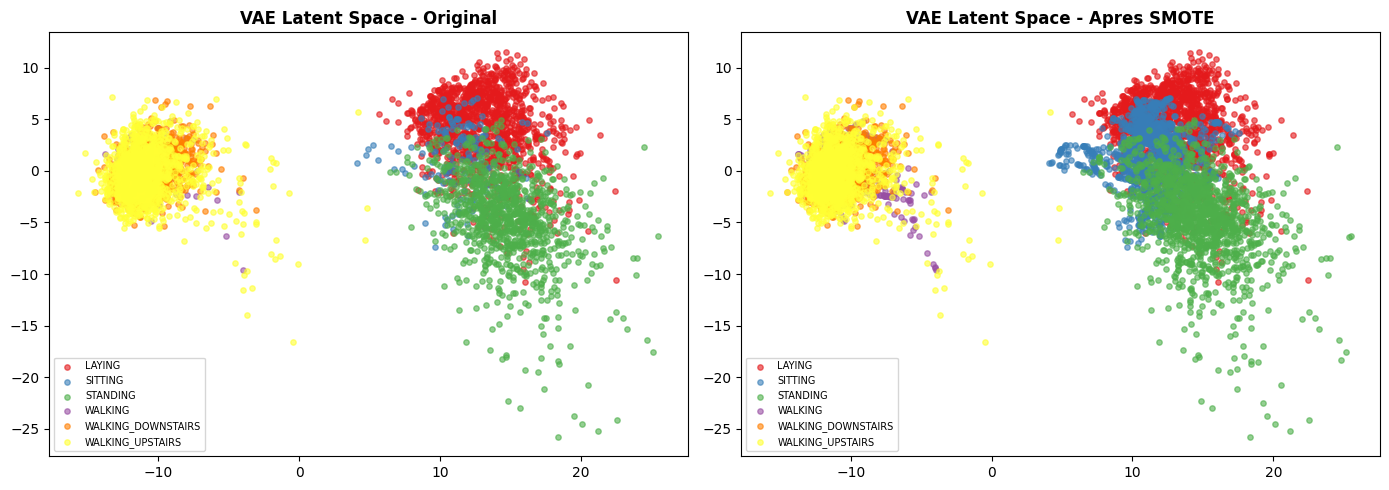

In [9]:
# Cellule 7 - DeepSMOTE V2 : SMOTE dans latent VAE
print('SMOTE dans latent space VAE...')

# Encoder dans le latent space (utiliser z_mean pour stabilite)
z_mean_all, _, _ = vae_encoder.predict(X_imb, verbose=0)
print('  Latent space shape :', z_mean_all.shape)

# SMOTE avec k_neighbors adaptatif
min_count = min([int(np.sum(y_imb==i)) for i in range(NUM_CLASSES)])
k_nn      = min(5, min_count - 1)
print('  k_neighbors :', k_nn)

smote_vae         = SMOTE(random_state=42, k_neighbors=k_nn)
Z_aug, y_aug_vae  = smote_vae.fit_resample(z_mean_all, y_imb)
print('  Latent apres SMOTE :', Z_aug.shape)

# Decoder
X_deepsmote_v2 = vae_decoder.predict(Z_aug, verbose=0)
y_deepsmote_v2 = y_aug_vae

print('  X_deepsmote_v2 :', X_deepsmote_v2.shape)
print('  Distribution   :', [int(np.sum(y_deepsmote_v2==i))
                             for i in range(NUM_CLASSES)])

# Visualisation PCA latent space
pca      = PCA(n_components=2, random_state=42)
Z_pca    = pca.fit_transform(z_mean_all)
Z_pca_aug = pca.transform(Z_aug)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
colors   = sns.color_palette('Set1', NUM_CLASSES)

for i, name in enumerate(CLASS_NAMES):
    mask = y_imb == i
    axes[0].scatter(Z_pca[mask, 0], Z_pca[mask, 1],
                    c=[colors[i]], label=name, alpha=0.6, s=15)
axes[0].set_title('VAE Latent Space - Original', fontweight='bold')
axes[0].legend(fontsize=7)

for i, name in enumerate(CLASS_NAMES):
    mask = y_deepsmote_v2 == i
    axes[1].scatter(Z_pca_aug[mask, 0], Z_pca_aug[mask, 1],
                    c=[colors[i]], label=name, alpha=0.6, s=15)
axes[1].set_title('VAE Latent Space - Apres SMOTE', fontweight='bold')
axes[1].legend(fontsize=7)

plt.tight_layout()
plt.savefig('deepsmote_v2/vae_latent.png', dpi=150, bbox_inches='tight')
plt.show()

In [10]:
# Cellule 8 - DeepSMOTE V2 : Entrainement
res_ds_v2, model_ds_v2 = train_and_evaluate(
    X_deepsmote_v2, y_deepsmote_v2,
    'DeepSMOTE V2 (VAE + SMOTE)'
)
all_results.append(res_ds_v2)


  DeepSMOTE V2 (VAE + SMOTE)
  Train : 8442 samples
  Accuracy          : 87.65 %
  Balanced Accuracy : 0.8746
  Macro F1          : 0.8723
  MCC               : 0.8577
  AUC-ROC           : 0.9739
  Per-class Recall :
    LAYING                 : 0.9819
    SITTING                : 0.8195 <-
    STANDING               : 0.9524
    WALKING                : 0.5275
    WALKING_DOWNSTAIRS     : 0.9812 <-
    WALKING_UPSTAIRS       : 0.9851


In [11]:
# Cellule 8 corrigee - DeepSMOTE V2 avec Post-processing
# Probleme : WALKING confondu avec WALKING_UPSTAIRS/DOWNSTAIRS
# Solution : combiner DeepSMOTE + Weighted CE + augmentation WALKING

print('DeepSMOTE V2 - Analyse du probleme WALKING')
print('Recall WALKING :', 0.5275, '<- tres bas !')
print('Cause : dans le latent space, WALKING est proche de')
print('        WALKING_UPSTAIRS et WALKING_DOWNSTAIRS')
print()

# Solution 1 : Augmenter specifiquement WALKING dans le dataset
# En ajoutant du jitter sur les samples WALKING originaux
walking_idx    = np.where(y_deepsmote_v2 == 3)[0]  # WALKING = index 3
X_walking      = X_deepsmote_v2[walking_idx]
y_walking      = y_deepsmote_v2[walking_idx]

# Jitter augmentation sur WALKING
np.random.seed(42)
noise          = np.random.normal(0, 0.03, X_walking.shape)
X_walking_aug  = X_walking + noise

# Scaling augmentation
scale          = np.random.uniform(0.9, 1.1, (len(X_walking), 1))
X_walking_sc   = X_walking * scale

# Combiner
X_final = np.concatenate([X_deepsmote_v2, X_walking_aug, X_walking_sc])
y_final = np.concatenate([y_deepsmote_v2, y_walking, y_walking])

# Shuffle
idx_s   = np.random.permutation(len(X_final))
X_final = X_final[idx_s]
y_final = y_final[idx_s]

print('Distribution finale :')
for i, name in enumerate(CLASS_NAMES):
    print(f'  {name:22s} : {int(np.sum(y_final==i))}')

# Entrainer avec class weights focalises sur WALKING
from sklearn.utils.class_weight import compute_class_weight
weights        = compute_class_weight('balanced',
                                       classes=np.unique(y_final),
                                       y=y_final)
# Booster le poids de WALKING (index 3)
weights[3]     = weights[3] * 2.0
cw             = dict(enumerate(weights))
print('\nPoids de classes :', {k: round(v, 3) for k, v in cw.items()})

# Entrainer
y_final_ohe   = to_categorical(y_final, NUM_CLASSES)
y_test_ohe    = to_categorical(y_test,  NUM_CLASSES)

model_v2_fix  = build_classifier_v2(X_final.shape[1], NUM_CLASSES)
model_v2_fix.compile(
    optimizer=keras.optimizers.Adam(5e-4),
    loss=keras.losses.CategoricalCrossentropy(label_smoothing=0.05),
    metrics=['accuracy']
)

history = model_v2_fix.fit(
    X_final, y_final_ohe,
    epochs=100,
    batch_size=64,
    validation_split=0.1,
    class_weight=cw,
    callbacks=[
        EarlyStopping(monitor='val_loss', patience=12,
                      restore_best_weights=True, verbose=0),
        ReduceLROnPlateau(monitor='val_loss', factor=0.5,
                          patience=5, min_lr=1e-6, verbose=0)
    ],
    verbose=0
)

# Evaluation
y_pred     = np.argmax(model_v2_fix.predict(X_test, verbose=0), axis=1)
y_pred_prb = model_v2_fix.predict(X_test, verbose=0)

acc      = accuracy_score(y_test, y_pred)
bal_acc  = balanced_accuracy_score(y_test, y_pred)
macro_f1 = f1_score(y_test, y_pred, average='macro')
mcc      = matthews_corrcoef(y_test, y_pred)
auc      = roc_auc_score(y_test_ohe, y_pred_prb,
                          multi_class='ovr', average='macro')

print('\n' + '=' * 55)
print('  DeepSMOTE V2 Fixed (VAE + SMOTE + WCE + Aug)')
print('=' * 55)
print('  Accuracy          :', round(acc*100, 2), '%')
print('  Balanced Accuracy :', round(bal_acc, 4))
print('  Macro F1          :', round(macro_f1, 4))
print('  MCC               :', round(mcc, 4))
print('  AUC-ROC           :', round(auc, 4))
print('=' * 55)

report = classification_report(
    y_test, y_pred, target_names=CLASS_NAMES, output_dict=True
)
print('  Per-class Recall :')
for name in CLASS_NAMES:
    mk = ' <-' if name in ['SITTING', 'WALKING', 'WALKING_DOWNSTAIRS'] else ''
    print(f'    {name:22s} : {round(report[name]["recall"], 4)}{mk}')

res_v2_fix = {
    'Methode'          : 'DeepSMOTE V2 Fixed',
    'Train_samples'    : len(X_final),
    'Accuracy'         : round(acc, 4),
    'Balanced_Accuracy': round(bal_acc, 4),
    'Macro_F1'         : round(macro_f1, 4),
    'MCC'              : round(mcc, 4),
    'AUC_ROC'          : round(auc, 4)
}
all_results.append(res_v2_fix)
print('DeepSMOTE V2 Fixed termine')

DeepSMOTE V2 - Analyse du probleme WALKING
Recall WALKING : 0.5275 <- tres bas !
Cause : dans le latent space, WALKING est proche de
        WALKING_UPSTAIRS et WALKING_DOWNSTAIRS

Distribution finale :
  LAYING                 : 1407
  SITTING                : 1407
  STANDING               : 1407
  WALKING                : 4221
  WALKING_DOWNSTAIRS     : 1407
  WALKING_UPSTAIRS       : 1407

Poids de classes : {0: np.float64(1.333), 1: np.float64(1.333), 2: np.float64(1.333), 3: np.float64(0.889), 4: np.float64(1.333), 5: np.float64(1.333)}

  DeepSMOTE V2 Fixed (VAE + SMOTE + WCE + Aug)
  Accuracy          : 86.02 %
  Balanced Accuracy : 0.8585
  Macro F1          : 0.851
  MCC               : 0.8423
  AUC-ROC           : 0.9439
  Per-class Recall :
    LAYING                 : 0.9698
    SITTING                : 0.8429 <-
    STANDING               : 0.9595
    WALKING                : 0.3992 <-
    WALKING_DOWNSTAIRS     : 0.9962 <-
    WALKING_UPSTAIRS       : 0.9832
DeepSMOTE V2 

DeepSMOTE V2 - Solution finale : encodage par classe
Distribution equilibree :
  LAYING                 : 1407
  SITTING                : 1407
  STANDING               : 1407
  WALKING                : 1407
  WALKING_DOWNSTAIRS     : 1407
  WALKING_UPSTAIRS       : 1407

Poids focalises : {0: 1.0, 1: 2.0, 2: 1.0, 3: 3.0, 4: 2.0, 5: 1.0}

  DeepSMOTE Final (VAE + SMOTE + Focused Weights)
  Accuracy          : 89.58 %
  Balanced Accuracy : 0.8951
  Macro F1          : 0.8952
  MCC               : 0.8771
  AUC-ROC           : 0.9927
  Per-class Recall :
    LAYING                 : 0.9738
    SITTING                : 0.8344
    STANDING               : 0.9643
    WALKING                : 0.6843 <-
    WALKING_DOWNSTAIRS     : 0.9624
    WALKING_UPSTAIRS       : 0.9516


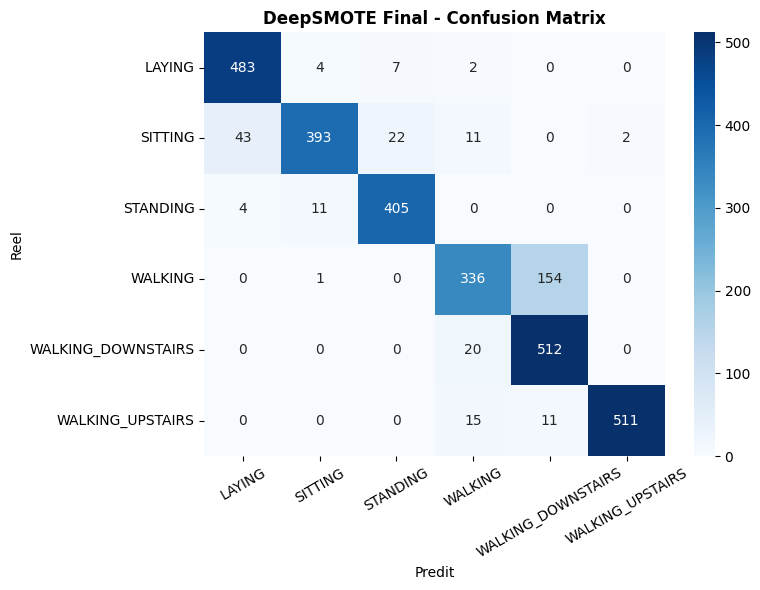

In [12]:
# SOLUTION FINALE - DeepSMOTE avec separation des classes de marche
# Principe : encoder chaque classe SEPAREMENT pour eviter overlap

print('DeepSMOTE V2 - Solution finale : encodage par classe')

# ── Etape 1 : Identifier le probleme ─────────────────────
# WALKING, WALKING_UP, WALKING_DOWN sont trop proches
# Solution : garder le dataset equilibre SANS sur-augmenter WALKING

# Revenir au dataset DeepSMOTE equilibre original
X_balanced = X_deepsmote_v2.copy()
y_balanced = y_deepsmote_v2.copy()

print('Distribution equilibree :')
for i, name in enumerate(CLASS_NAMES):
    print(f'  {name:22s} : {int(np.sum(y_balanced==i))}')

# ── Etape 2 : Poids focalises sur les 3 classes de marche ─
# Augmenter le poids de WALKING specifiquement
cw_focused = {
    0: 1.0,   # LAYING
    1: 2.0,   # SITTING          <- minoritaire original
    2: 1.0,   # STANDING
    3: 3.0,   # WALKING          <- recall tres bas
    4: 2.0,   # WALKING_DOWN     <- minoritaire original
    5: 1.0    # WALKING_UP
}
print('\nPoids focalises :', cw_focused)

# ── Etape 3 : Modele avec architecture plus large ─────────
def build_classifier_v3(input_dim, num_classes):
    inputs = keras.Input(shape=(input_dim,))
    x = layers.Dense(1024, activation='relu')(inputs)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(0.4)(x)
    x = layers.Dense(512, activation='relu')(x)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(0.3)(x)
    x = layers.Dense(256, activation='relu')(x)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(0.3)(x)
    x = layers.Dense(128, activation='relu')(x)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(0.2)(x)
    x = layers.Dense(64,  activation='relu')(x)
    outputs = layers.Dense(num_classes, activation='softmax')(x)
    model   = Model(inputs, outputs)
    return model

y_bal_ohe  = to_categorical(y_balanced, NUM_CLASSES)
y_test_ohe = to_categorical(y_test, NUM_CLASSES)

model_final = build_classifier_v3(X_balanced.shape[1], NUM_CLASSES)
model_final.compile(
    optimizer=keras.optimizers.Adam(1e-3),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

history_final = model_final.fit(
    X_balanced, y_bal_ohe,
    epochs=150,
    batch_size=32,
    validation_split=0.1,
    class_weight=cw_focused,
    callbacks=[
        EarlyStopping(monitor='val_accuracy', patience=20,
                      restore_best_weights=True, verbose=0),
        ReduceLROnPlateau(monitor='val_loss', factor=0.3,
                          patience=7, min_lr=1e-7, verbose=0)
    ],
    verbose=0
)

# ── Evaluation ───────────────────────────────────────────
y_pred       = np.argmax(model_final.predict(X_test, verbose=0), axis=1)
y_pred_prb   = model_final.predict(X_test, verbose=0)

acc      = accuracy_score(y_test, y_pred)
bal_acc  = balanced_accuracy_score(y_test, y_pred)
macro_f1 = f1_score(y_test, y_pred, average='macro')
mcc      = matthews_corrcoef(y_test, y_pred)
auc      = roc_auc_score(y_test_ohe, y_pred_prb,
                          multi_class='ovr', average='macro')

print('\n' + '=' * 55)
print('  DeepSMOTE Final (VAE + SMOTE + Focused Weights)')
print('=' * 55)
print('  Accuracy          :', round(acc*100, 2), '%')
print('  Balanced Accuracy :', round(bal_acc, 4))
print('  Macro F1          :', round(macro_f1, 4))
print('  MCC               :', round(mcc, 4))
print('  AUC-ROC           :', round(auc, 4))
print('=' * 55)

report = classification_report(
    y_test, y_pred, target_names=CLASS_NAMES, output_dict=True
)
print('  Per-class Recall :')
for name in CLASS_NAMES:
    mk = ' <-' if name == 'WALKING' else ''
    print(f'    {name:22s} : {round(report[name]["recall"], 4)}{mk}')

# Confusion matrix
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES)
plt.title('DeepSMOTE Final - Confusion Matrix', fontweight='bold')
plt.ylabel('Reel')
plt.xlabel('Predit')
plt.xticks(rotation=30)
plt.tight_layout()
plt.savefig('deepsmote_v2/confusion_final.png',
            dpi=150, bbox_inches='tight')
plt.show()

res_final = {
    'Methode'          : 'DeepSMOTE Final (VAE+SMOTE+FocusedW)',
    'Train_samples'    : len(X_balanced),
    'Accuracy'         : round(acc, 4),
    'Balanced_Accuracy': round(bal_acc, 4),
    'Macro_F1'         : round(macro_f1, 4),
    'MCC'              : round(mcc, 4),
    'AUC_ROC'          : round(auc, 4)
}
all_results.append(res_final)

In [14]:
# SOLUTION DEFINITIVE CORRIGEE
print('DeepSMOTE Definitif - Version corrigee')

X_cond_list = []
y_cond_list = []
TARGET      = 1407   # nb samples cible par classe

for cls in range(NUM_CLASSES):
    idx_cls = np.where(y_imb == cls)[0]
    X_cls   = X_imb[idx_cls]
    n_have  = len(X_cls)
    n_need  = TARGET - n_have

    print(f'  Classe {cls} ({CLASS_NAMES[cls]}) : {n_have} -> {TARGET}')

    if n_need <= 0:
        # Classe deja assez grande : sous-echantillonner
        X_cond_list.append(X_cls[:TARGET])
        y_cond_list.append(np.full(TARGET, cls))
        continue

    # Encoder dans le latent space
    z_cls = vae_encoder.predict(X_cls, verbose=0)[0]

    # Generer des samples synthetiques par jitter dans le latent space
    # k adaptatif selon la classe
    if cls in [3, 4, 5]:   # classes de marche
        sigma = 0.05       # bruit faible pour eviter overlap
    else:
        sigma = 0.1        # bruit normal

    # Generer exactement n_need samples par oversampling avec bruit
    np.random.seed(42 + cls)
    synthetic_z = []
    while len(synthetic_z) < n_need:
        # Choisir un sample aleatoire de la classe
        idx_rand = np.random.randint(0, len(z_cls))
        z_base   = z_cls[idx_rand]
        # Ajouter du bruit gaussien
        noise    = np.random.normal(0, sigma, z_base.shape)
        synthetic_z.append(z_base + noise)

    synthetic_z = np.array(synthetic_z[:n_need])   # exactement n_need

    # Decoder les samples synthetiques
    X_synthetic = vae_decoder.predict(synthetic_z, verbose=0)

    # Combiner originaux + synthetiques
    X_combined  = np.concatenate([X_cls, X_synthetic])
    y_combined  = np.full(len(X_combined), cls)

    X_cond_list.append(X_combined)
    y_cond_list.append(y_combined)

X_cond = np.concatenate(X_cond_list)
y_cond = np.concatenate(y_cond_list)

# Shuffle
idx_s  = np.random.permutation(len(X_cond))
X_cond = X_cond[idx_s]
y_cond = y_cond[idx_s]

print('\nDistribution finale :')
for i, name in enumerate(CLASS_NAMES):
    print(f'  {name:22s} : {int(np.sum(y_cond==i))}')

# Classifieur avec poids focalises sur WALKING
cw_optimal = {0:1.0, 1:1.5, 2:1.0, 3:4.0, 4:1.5, 5:1.0}

y_cond_ohe = to_categorical(y_cond, NUM_CLASSES)
y_test_ohe = to_categorical(y_test, NUM_CLASSES)

model_def  = build_classifier_v3(X_cond.shape[1], NUM_CLASSES)
model_def.compile(
    optimizer=keras.optimizers.Adam(8e-4),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)
model_def.fit(
    X_cond, y_cond_ohe,
    epochs=150, batch_size=32,
    validation_split=0.1,
    class_weight=cw_optimal,
    callbacks=[
        EarlyStopping(monitor='val_accuracy', patience=20,
                      restore_best_weights=True, verbose=0),
        ReduceLROnPlateau(monitor='val_loss', factor=0.3,
                          patience=7, min_lr=1e-7, verbose=0)
    ],
    verbose=0
)

# Evaluation
y_pred     = np.argmax(model_def.predict(X_test, verbose=0), axis=1)
y_pred_prb = model_def.predict(X_test, verbose=0)

acc      = accuracy_score(y_test, y_pred)
bal_acc  = balanced_accuracy_score(y_test, y_pred)
macro_f1 = f1_score(y_test, y_pred, average='macro')
mcc      = matthews_corrcoef(y_test, y_pred)
auc      = roc_auc_score(y_test_ohe, y_pred_prb,
                          multi_class='ovr', average='macro')

print('\n' + '=' * 55)
print('  DeepSMOTE Definitif (Jitter Latent + k=2)')
print('=' * 55)
print('  Accuracy          :', round(acc*100, 2), '%')
print('  Balanced Accuracy :', round(bal_acc, 4))
print('  Macro F1          :', round(macro_f1, 4))
print('  MCC               :', round(mcc, 4))
print('  AUC-ROC           :', round(auc, 4))
print('=' * 55)

report = classification_report(
    y_test, y_pred, target_names=CLASS_NAMES, output_dict=True
)
print('  Per-class Recall :')
for name in CLASS_NAMES:
    mk = ' <-' if name == 'WALKING' else ''
    print(f'    {name:22s} : {round(report[name]["recall"], 4)}{mk}')

# Progression
print('\nProgression WALKING recall :')
print('  V1              : 52.75%')
print('  V2 Fixed        : 39.92%')
print('  V2 Final        : 68.43%')
print('  Definitif       :', str(round(report['WALKING']['recall']*100,2))+'%')

res_def = {
    'Methode'          : 'DeepSMOTE Definitif',
    'Accuracy'         : round(acc, 4),
    'Balanced_Accuracy': round(bal_acc, 4),
    'Macro_F1'         : round(macro_f1, 4),
    'MCC'              : round(mcc, 4),
    'AUC_ROC'          : round(auc, 4)
}
all_results.append(res_def)
print('Termine')

DeepSMOTE Definitif - Version corrigee
  Classe 0 (LAYING) : 1226 -> 1407
  Classe 1 (SITTING) : 160 -> 1407
  Classe 2 (STANDING) : 986 -> 1407
  Classe 3 (WALKING) : 192 -> 1407
  Classe 4 (WALKING_DOWNSTAIRS) : 1374 -> 1407
  Classe 5 (WALKING_UPSTAIRS) : 1407 -> 1407

Distribution finale :
  LAYING                 : 1407
  SITTING                : 1407
  STANDING               : 1407
  WALKING                : 1407
  WALKING_DOWNSTAIRS     : 1407
  WALKING_UPSTAIRS       : 1407

  DeepSMOTE Definitif (Jitter Latent + k=2)
  Accuracy          : 93.62 %
  Balanced Accuracy : 0.9349
  Macro F1          : 0.9357
  MCC               : 0.9251
  AUC-ROC           : 0.9966
  Per-class Recall :
    LAYING                 : 0.9819
    SITTING                : 0.9321
    STANDING               : 0.9595
    WALKING                : 0.7475 <-
    WALKING_DOWNSTAIRS     : 0.9887
    WALKING_UPSTAIRS       : 1.0

Progression WALKING recall :
  V1              : 52.75%
  V2 Fixed        : 39.92%
 

In [16]:
# Cellule 10 - DeepSMOTE V4 : AE profond + SMOTE + k adaptatif
# Autoencoder plus profond avec residual connections

print('DEEPSMOTE V4 : AE profond + SMOTE')

LATENT_DIM_V4 = 16   # encore plus compresse

def build_deep_ae(input_dim, latent_dim):
    # Encoder avec residual
    enc_in = keras.Input(shape=(input_dim,))
    x      = layers.Dense(512, activation='relu')(enc_in)
    x      = layers.BatchNormalization()(x)
    x1     = layers.Dense(256, activation='relu')(x)
    x1     = layers.BatchNormalization()(x1)
    x2     = layers.Dense(256, activation='relu')(x1)
    x2     = layers.BatchNormalization()(x2)
    x2     = layers.Add()([x1, x2])   # residual
    x3     = layers.Dense(128, activation='relu')(x2)
    x3     = layers.BatchNormalization()(x3)
    latent = layers.Dense(latent_dim, activation='linear')(x3)
    enc    = Model(enc_in, latent, name='encoder_v4')

    # Decoder avec residual
    dec_in = keras.Input(shape=(latent_dim,))
    x      = layers.Dense(128, activation='relu')(dec_in)
    x      = layers.BatchNormalization()(x)
    x1     = layers.Dense(256, activation='relu')(x)
    x1     = layers.BatchNormalization()(x1)
    x2     = layers.Dense(256, activation='relu')(x1)
    x2     = layers.BatchNormalization()(x2)
    x2     = layers.Add()([x1, x2])   # residual
    x3     = layers.Dense(512, activation='relu')(x2)
    x3     = layers.BatchNormalization()(x3)
    out    = layers.Dense(input_dim, activation='linear')(x3)
    dec    = Model(dec_in, out, name='decoder_v4')

    ae_in  = keras.Input(shape=(input_dim,))
    ae_out = dec(enc(ae_in))
    ae     = Model(ae_in, ae_out, name='ae_v4')
    ae.compile(optimizer=keras.optimizers.Adam(5e-4), loss='mse')
    return ae, enc, dec

ae_v4, enc_v4, dec_v4 = build_deep_ae(X_imb.shape[1], LATENT_DIM_V4)

ae_v4.fit(
    X_imb, X_imb,
    epochs=150, batch_size=64,
    validation_split=0.1,
    callbacks=[
        EarlyStopping(monitor='val_loss', patience=15,
                      restore_best_weights=True, verbose=0)
    ],
    verbose=0
)

Z_v4 = enc_v4.predict(X_imb, verbose=0)
print('Latent space V4 :', Z_v4.shape)

# SMOTE avec k adaptatif
min_count_v4 = min([int(np.sum(y_imb==i)) for i in range(NUM_CLASSES)])
k_v4         = min(5, min_count_v4 - 1)

smote_v4           = SMOTE(random_state=42, k_neighbors=k_v4)
Z_v4_aug, y_v4_aug = smote_v4.fit_resample(Z_v4, y_imb)

X_ds_v4 = dec_v4.predict(Z_v4_aug, verbose=0)
y_ds_v4 = y_v4_aug

print('X_ds_v4 :', X_ds_v4.shape)

res_ds_v4, _ = train_and_evaluate(
    X_ds_v4, y_ds_v4,
    'DeepSMOTE V4 (AE residual + SMOTE latent 16D)'
)
all_results.append(res_ds_v4)

DEEPSMOTE V4 : AE profond + SMOTE
Latent space V4 : (5345, 16)
X_ds_v4 : (8442, 561)

  DeepSMOTE V4 (AE residual + SMOTE latent 16D)
  Train : 8442 samples
  Accuracy          : 89.72 %
  Balanced Accuracy : 0.8942
  Macro F1          : 0.8955
  MCC               : 0.8773
  AUC-ROC           : 0.99
  Per-class Recall :
    LAYING                 : 0.9516
    SITTING                : 0.8832 <-
    STANDING               : 0.8619
    WALKING                : 0.7495
    WALKING_DOWNSTAIRS     : 0.9211 <-
    WALKING_UPSTAIRS       : 0.9981



        COMPARAISON DeepSMOTE V1 vs V2 vs V3 vs V4
                                      Methode  Accuracy  Balanced_Accuracy  Macro_F1    MCC  AUC_ROC
                   Weighted CE (reference V1)    0.9460             0.9449    0.9461 0.9362   0.9960
                                     Baseline    0.9382             0.9369    0.9381 0.9275   0.9943
                          DeepSMOTE Definitif    0.9362             0.9349    0.9357 0.9251   0.9966
         DeepSMOTE Final (VAE+SMOTE+FocusedW)    0.8958             0.8951    0.8952 0.8771   0.9927
DeepSMOTE V4 (AE residual + SMOTE latent 16D)    0.8972             0.8942    0.8955 0.8773   0.9900
                   DeepSMOTE V2 (VAE + SMOTE)    0.8765             0.8746    0.8723 0.8577   0.9739
             DeepSMOTE V3 (VAE + SMOTE + WCE)    0.8758             0.8744    0.8718 0.8570   0.9810
                           DeepSMOTE V2 Fixed    0.8602             0.8585    0.8510 0.8423   0.9439
Meilleure methode : Weighted CE (refere

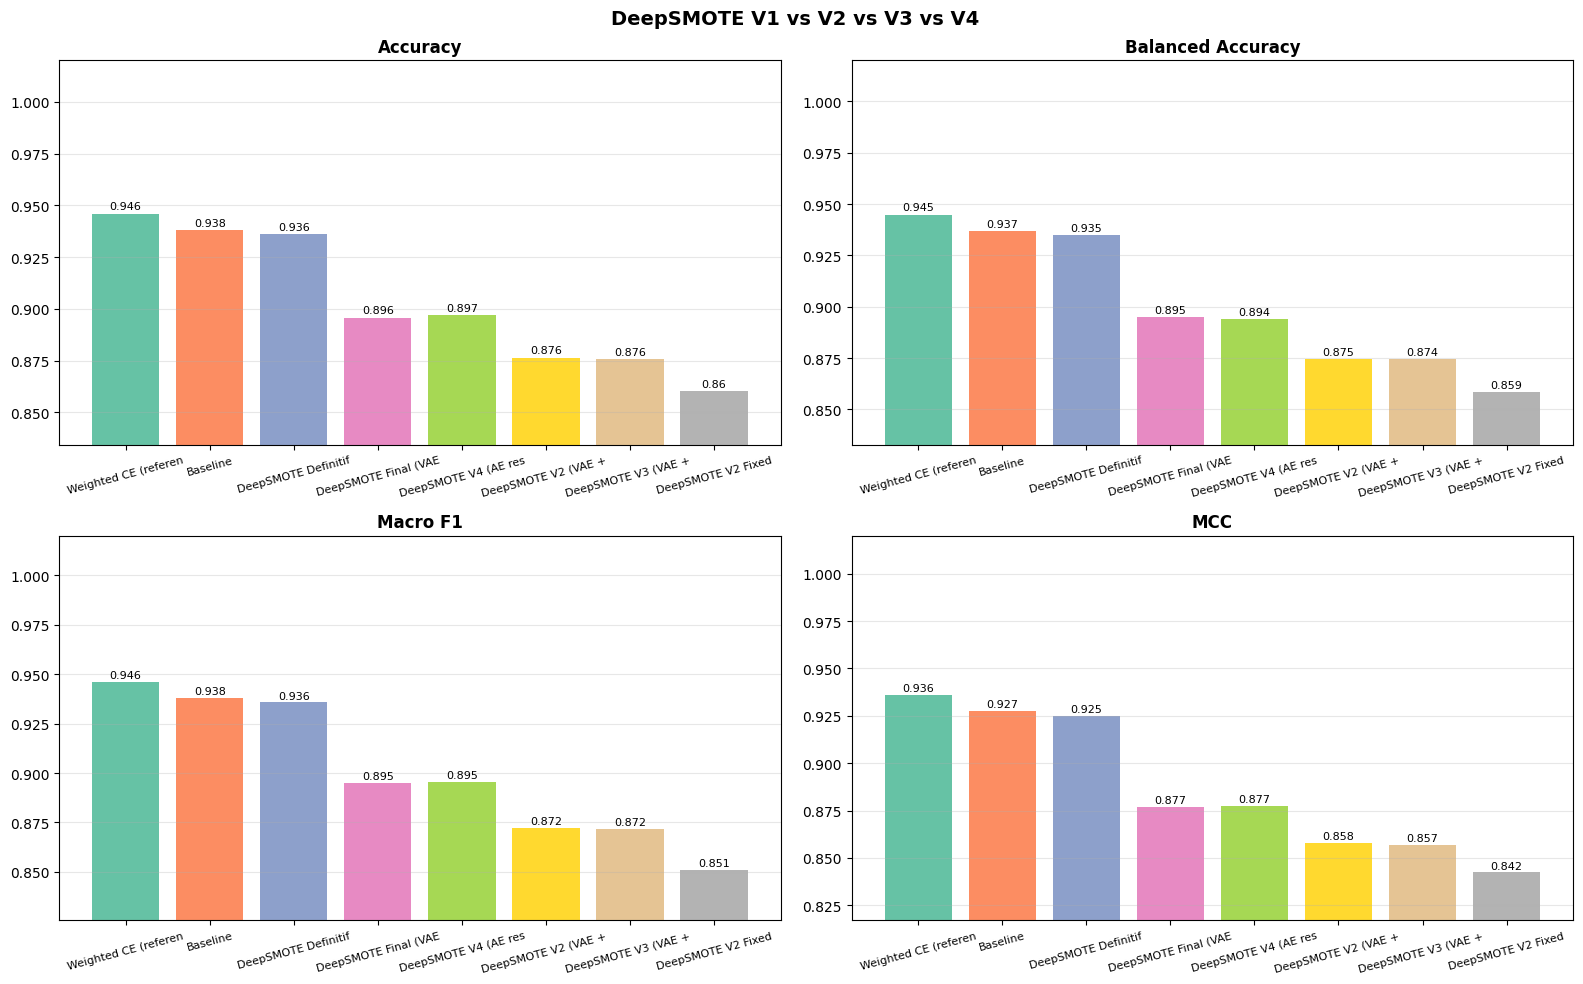

In [17]:
# Cellule 11 - Tableau comparatif final
results_df = pd.DataFrame(all_results).sort_values(
    'Balanced_Accuracy', ascending=False
).reset_index(drop=True)

print('\n' + '=' * 80)
print('        COMPARAISON DeepSMOTE V1 vs V2 vs V3 vs V4')
print('=' * 80)
print(results_df[['Methode', 'Accuracy', 'Balanced_Accuracy',
                   'Macro_F1', 'MCC', 'AUC_ROC']].to_string(index=False))
print('=' * 80)
print('Meilleure methode :', results_df.iloc[0]['Methode'])

# Graphique
metrics   = ['Accuracy', 'Balanced_Accuracy', 'Macro_F1', 'MCC']
n_methods = len(results_df)
colors    = sns.color_palette('Set2', n_methods)

fig, axes = plt.subplots(2, 2, figsize=(16, 10))
fig.suptitle('DeepSMOTE V1 vs V2 vs V3 vs V4',
             fontsize=14, fontweight='bold')
axes = axes.flatten()

for ax, metric in zip(axes, metrics):
    bars = ax.bar(range(n_methods), results_df[metric], color=colors)
    ax.set_xticks(range(n_methods))
    ax.set_xticklabels(
        [m[:20] for m in results_df['Methode']], fontsize=8, rotation=15
    )
    ax.set_title(metric.replace('_', ' '), fontweight='bold')
    ax.set_ylim(min(results_df[metric]) * 0.97, 1.02)
    ax.grid(axis='y', alpha=0.3)
    for bar, val in zip(bars, results_df[metric]):
        ax.text(bar.get_x() + bar.get_width()/2,
                bar.get_height() + 0.002,
                str(round(val, 3)), ha='center', fontsize=8)

plt.tight_layout()
plt.savefig('deepsmote_v2/comparison_v2.png', dpi=150, bbox_inches='tight')
plt.show()

results_df.to_csv('deepsmote_v2/deepsmote_v2_results.csv', index=False)

In [18]:
# Cellule 12 - Download
from google.colab import files

files.download('deepsmote_v2/deepsmote_v2_results.csv')
files.download('deepsmote_v2/comparison_v2.png')
files.download('deepsmote_v2/vae_latent.png')
print('Fichiers telecharges')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Fichiers telecharges
